In [22]:
import networkx as nx
import matplotlib.pyplot as plt

def google_like_alterative_paths(G, source, target, k=3, penalty=1.5):
    # Copia il grafo per non rovinare quello originale
    G_temp = G.copy()
    paths = []
    
    for _ in range(k):
        try:
            # Calcola il cammino minimo corrente basato sul peso
            path = nx.shortest_path(G_temp, source=source, target=target, weight='weight')
            paths.append(path)
            
            # Penalizza gli archi del cammino appena trovato
            for i in range(len(path) - 1):
                u, v = path[i], path[i+1]
                
                if G_temp.has_edge(u, v):
                    # Essendo un grafo standard (non un multigrafo), modifichiamo direttamente la chiave 'weight'
                    if 'weight' in G_temp[u][v]:
                        G_temp[u][v]['weight'] *= penalty
                            
        except nx.NetworkXNoPath:
            # Se non ci sono più strade possibili, si ferma
            break
            
    return paths

In [27]:
# Crea il tuo grafo di esempio
G = nx.Graph()
G.add_weighted_edges_from([
    (1, 2, 1),
    (2, 3, 1),
    (1, 3, 2),
    (3, 4, 1),
    (2, 4, 2),
    (1, 5, 3),
    (5, 4, 1),
    (2, 5, 1),
    (3, 5, 1),
    (4, 5, 1),
    (1, 6, 2),
    (6, 4, 1),
    (2, 6, 1),
    (3, 6, 1),
    (5, 6, 1),
    (4, 6, 1)
])

source = 1
target = 6
k = 3
penalty = 2

# Chiamata alla funzione corretta
alternative_paths = google_like_alterative_paths(G, source, target, k, penalty)

print(f"Alternative paths from {source} to {target}:")
for idx, path in enumerate(alternative_paths):
    print(f"Path {idx + 1}: {path}")

Alternative paths from 1 to 6:
Path 1: [1, 6]
Path 2: [1, 2, 6]
Path 3: [1, 3, 6]


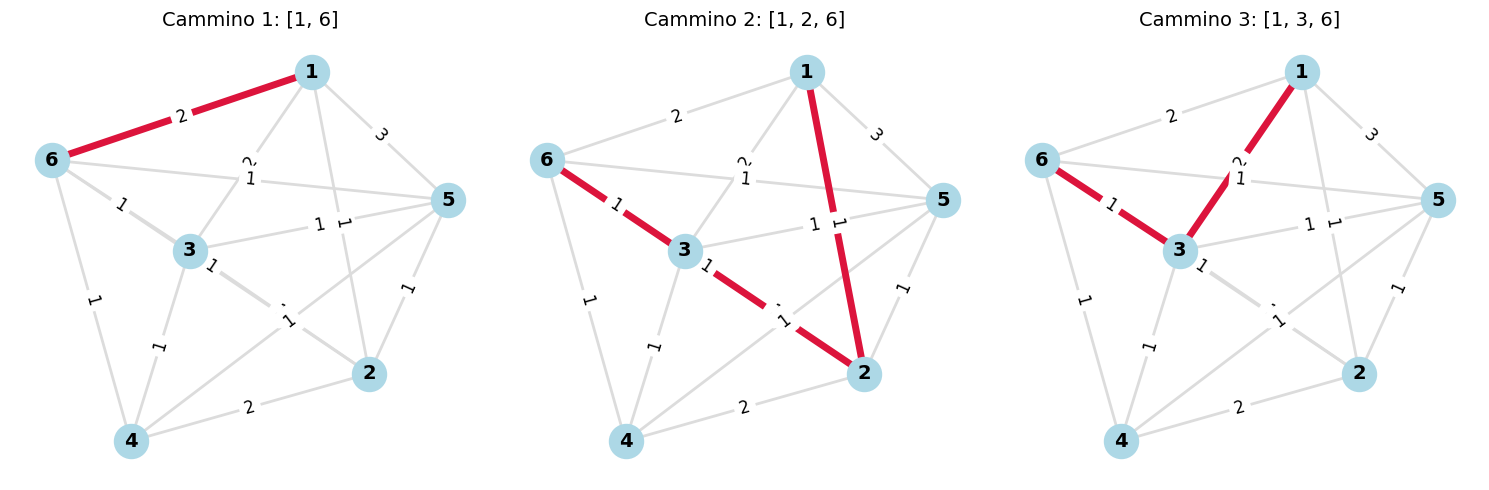

In [28]:
# 2. Calcola un layout fisso per i nodi, così la forma del grafo resta identica in tutti i plot
pos = nx.spring_layout(G, seed=42) 

# 3. Configura la griglia di grafici (1 riga, N colonne in base ai cammini trovati)
num_paths = len(alternative_paths)
fig, axes = plt.subplots(1, num_paths, figsize=(5 * num_paths, 5))

# Se viene trovato un solo cammino, axes non è una lista, lo trasformiamo in lista per il ciclo
if num_paths == 1:
    axes = [axes]

# 4. Disegna ogni cammino nel suo rispettivo sotto-grafico
for idx, path in enumerate(alternative_paths):
    ax = axes[idx]
    ax.set_title(f"Cammino {idx + 1}: {path}", fontsize=14)
    
    # Trasforma la lista dei nodi del cammino in una lista di coppie di archi
    # Es: [1, 2, 3, 4] -> [(1, 2), (2, 3), (3, 4)]
    path_edges = list(zip(path[:-1], path[1:]))
    
    # Disegna la struttura di base del grafo (nodi e tutti gli archi in grigio)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color='lightblue', node_size=600)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=14, font_weight='bold')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='gainsboro', width=2)
    
    # Evidenzia sopra gli archi del cammino corrente (in rosso e più spessi)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=path_edges, edge_color='crimson', width=5)
    
    # Mostra i pesi degli archi originali
    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, ax=ax, font_size=12)
    
    ax.axis('off') # Nasconde gli assi x e y per pulizia visiva

plt.tight_layout()
plt.show()